In [5]:
from google_play_scraper import Sort, reviews
import pandas as pd
import numpy as np

# Step 1: Scraping ulasan aplikasi Ruangguru
result, continuation_token = reviews(
    'com.ruangguru.livestudents',  # Package name aplikasi Ruangguru
    lang='id',                     # Bahasa Indonesia
    country='id',                  # Negara Indonesia
    sort=Sort.MOST_RELEVANT,       # Ulasan paling relevan
    count=1000,                    # Jumlah ulasan yang diambil
    filter_score_with=None         # Semua rating
)

# Step 2: Mengubah hasil scraping menjadi DataFrame
df_reviews = pd.DataFrame(np.array(result), columns=['review'])
df_reviews = df_reviews.join(
    pd.DataFrame(df_reviews.pop('review').tolist())
)

# Step 3: Memilih kolom yang relevan
new_df = df_reviews[['userName', 'score', 'at', 'content']]

# Step 4: Mengurutkan ulasan berdasarkan tanggal terbaru
sorted_df = new_df.sort_values(
    by='at',
    ascending=False
)

# Step 5: Menyimpan data ke CSV
my_df = sorted_df[['userName', 'score', 'at', 'content']]

my_df.to_csv(
    "/Users/mochammadmarillivio/Analisis Big Data/sentimen/scrapped_data.csv",
    index=False
)

# Step 6: Menampilkan hasil
print("Jumlah ulasan:", len(my_df))
print("Data berhasil disimpan ke file CSV.")

display(my_df.head())

Jumlah ulasan: 1000
Data berhasil disimpan ke file CSV.


,userName,score,at,content
106,Shafa Anindya Putri,5,2026-09-19 10:32:15,apk ini membatu bgt. kalau aku ga paham sana m...
88,FaizelMEET,4,2026-09-19 10:31:20,ruangguru bagus banget.. saya disabilitas Tuli...
3,Meri Diasari,4,2026-09-18 16:02:32,"Terima kasih, mentornya sangat baik dan penyam..."
5,syakira alwakia,1,2026-09-18 11:00:01,"metode pengajaranya bagust, tpi bebrpa sales n..."
24,Saya Kenzi,5,2026-09-17 19:47:38,belajar jadi lebih menyenangkan dan gampang bu...


In [13]:
import re, json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve, roc_auc_score)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Negatif": "#EF4444", "Netral": "#F59E0B", "Positif": "#10B981"}
SEED = 42

In [18]:
SCRAPE = False                  # True = scraping ulang dari Play Store
DATA_PATH = "scrapped_data.csv" # ubah sesuai lokasi file Anda
APP_ID = "com.ruangguru.livestudents"
N_REVIEWS = 1000

if SCRAPE:
    from google_play_scraper import Sort, reviews
    result, _ = reviews(APP_ID, lang="id", country="id", sort=Sort.MOST_RELEVANT, count=N_REVIEWS)
    df_raw = pd.DataFrame(result)[["userName", "score", "at", "content"]]
    df_raw = df_raw.sort_values("at", ascending=False)
    df_raw.to_csv(DATA_PATH, index=False)
else:
    df_raw = pd.read_csv(DATA_PATH, encoding="utf-8")

# Validasi kolom & buang data kosong
assert {"score", "content"}.issubset(df_raw.columns), "Kolom 'score' dan 'content' wajib ada"
df = df_raw.dropna(subset=["content", "score"]).copy()
df["at"] = pd.to_datetime(df["at"], errors="coerce")
df = df.reset_index(drop=True)
print(f"Data dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Data dimuat: 1000 baris, 4 kolom


,userName,score,at,content
0,Shafa Anindya Putri,5,2026-09-19 10:32:15,apk ini membatu bgt. kalau aku ga paham sana m...
1,FaizelMEET,4,2026-09-19 10:31:20,ruangguru bagus banget.. saya disabilitas Tuli...
2,Meri Diasari,4,2026-09-18 16:02:32,"Terima kasih, mentornya sangat baik dan penyam..."
3,syakira alwakia,1,2026-09-18 11:00:01,"metode pengajaranya bagust, tpi bebrpa sales n..."
4,Saya Kenzi,5,2026-09-17 19:47:38,belajar jadi lebih menyenangkan dan gampang bu...


In [19]:
# 2. Eksplorasi Data (EDA)

print(df.info())
print("\nMissing value:\n", df.isna().sum())
print(f"\nRentang tanggal: {df['at'].min():%d %b %Y} - {df['at'].max():%d %b %Y}")
print(f"Ulasan duplikat: {df.duplicated(subset='content').sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   userName  1000 non-null   str           
 1   score     1000 non-null   int64         
 2   at        1000 non-null   datetime64[us]
 3   content   1000 non-null   str           
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 352.0 KB
None

Missing value:
 userName    0
score       0
at          0
content     0
dtype: int64

Rentang tanggal: 15 Sep 2018 - 19 Sep 2026
Ulasan duplikat: 2


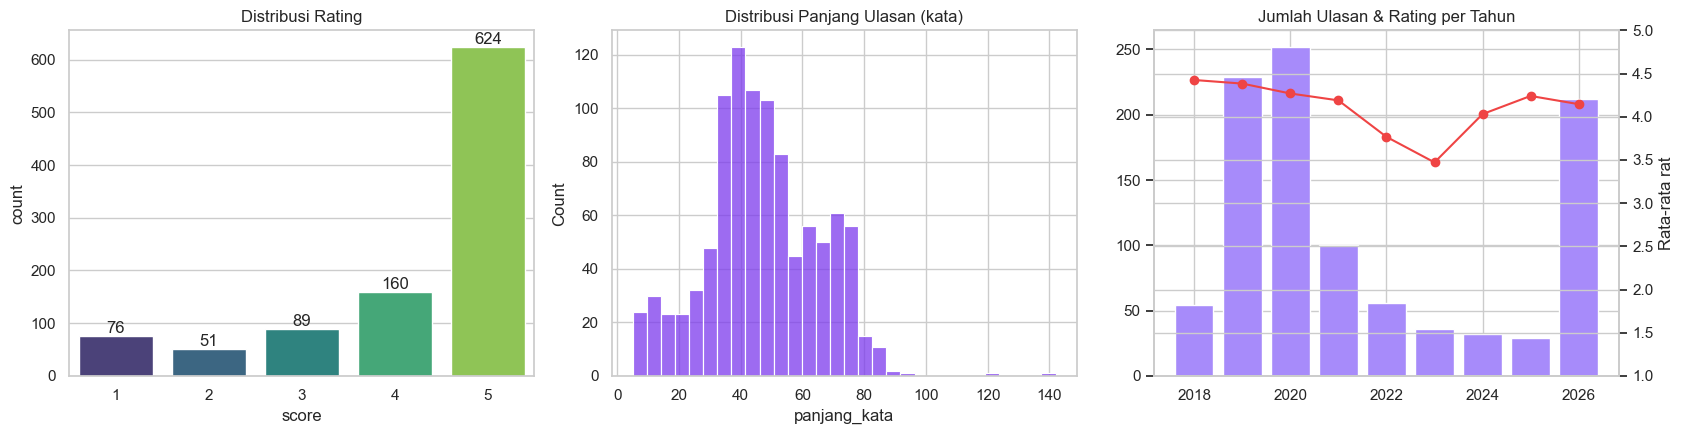

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

sns.countplot(data=df, x="score", palette="viridis", ax=ax[0])
ax[0].set_title("Distribusi Rating")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

df["panjang_kata"] = df["content"].astype(str).str.split().str.len()
sns.histplot(df["panjang_kata"], bins=30, color="#7C3AED", ax=ax[1])
ax[1].set_title("Distribusi Panjang Ulasan (kata)")

yr = df.dropna(subset=["at"]).groupby(df["at"].dt.year).agg(jumlah=("score", "size"), rating=("score", "mean"))
ax[2].bar(yr.index, yr["jumlah"], color="#A78BFA")
ax2 = ax[2].twinx(); ax2.plot(yr.index, yr["rating"], color="#EF4444", marker="o"); ax2.set_ylim(1, 5); ax2.set_ylabel("Rata-rata rat")
ax[2].set_title("Jumlah Ulasan & Rating per Tahun")
plt.tight_layout(); plt.show()

label
Positif    784
Negatif    127
Netral      89
Name: count, dtype: int64
label
Positif    78.4 %
Negatif    12.7 %
Netral      8.9 %
Name: count, dtype: str


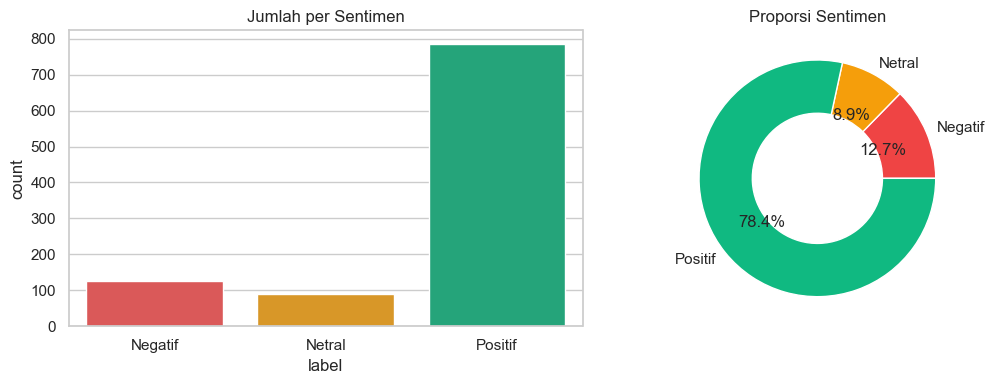

In [21]:
def beri_label(score):
    if score <= 2: return "Negatif"
    if score == 3: return "Netral"
    return "Positif"

df["label"] = df["score"].apply(beri_label)
dist = df["label"].value_counts()
print(dist)
print((dist / dist.sum() * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = ["Negatif", "Netral", "Positif"]
sns.countplot(data=df, x="label", order=order, palette=PALETTE, ax=ax[0]); ax[0].set_title("Jumlah per Sentimen")
ax[1].pie(dist[order], labels=order, autopct="%1.1f%%", colors=[PALETTE[o] for o in order], wedgeprops=dict(width=.45))
ax[1].set_title("Proporsi Sentimen"); plt.tight_layout(); plt.show()

In [31]:
STOPWORDS = {
    "di", "dari", "ke", "pada", "dengan", "untuk", "oleh", "tentang", "kepada", "yang", "dan", "atau", "tetapi", "tapi", 
    "karena", "meskipun", "jika", "agar", "saya", "aku", "kamu", "dia", "kita", "mereka", "ini", "itu", "lah", "tuh", "nya", 
    "dong", "aja", "gitu", "deh", "emang", "ya", "sih", "kok", "lho", "nih", "si", "pun", "juga", "sudah", "akan", "lagi", 
    "pernah", "hanya", "adalah", "dalam", "ada", "para", "sebagai", "saat", "ketika", "kalau", "kalo", "jadi", "sama", "mau"
}
NEGATIONS = {"tidak", "bukan", "belum", "jangan", "kurang", "gak", "ga", "nggak", "ngga", "tak", "gk", "enggak"}
DOMAIN_STOPWORDS = {"ruangguru", "rg", "ruang", "kak"}  # nama aplikasi: muncul di hampir semua ulasan

SLANG = {
    "gak": "tidak", "ga": "tidak", "nggak": "tidak", "ngga": "tidak", "gk": "tidak", "enggak": "tidak", "tdk": "tidak", "tak": "tidak",
    "bgt": "banget", "bgus": "bagus", "bags": "bagus", "bagust": "bagus", "mantul": "mantap", "udh": "sudah", "udah": "sudah", 
    "sdh": "sudah", "blm": "belum", "yg": "yang", "dgn": "dengan", "krn": "karena", "karna": "karena", "utk": "untuk", "jd": "jadi", 
    "tp": "tapi", "tpi": "tapi", "klo": "kalau", "kalo": "kalau", "sy": "saya", "sm": "sama", "sma": "sama", "bs": "bisa", "bsa": "bisa",
    "gabisa": "tidak bisa", "lemot": "lambat", "lag": "lambat", "ngelag": "lambat", "eror": "error", "erorr": "error", 
    "apk": "aplikasi", "app": "aplikasi", "aplikasinya": "aplikasi", "thx": "terima kasih", "makasih": "terima kasih",
    "terimakasih": "terima kasih", "trims": "terima kasih", "oke": "ok", "okey": "ok", "recomended": "recommended", 
    "rekomen": "recommended", "kereen": "keren", "jelek": "buruk", "jlek": "buruk", "pake": "pakai", "pke": "pakai", 
    "jg": "juga", "dr": "dari", "dl": "dulu", "bgmn": "bagaimana", "gmn": "bagaimana", "knp": "kenapa", "kyk": "seperti", 
    "bnyk": "banyak", "bebrpa": "beberapa"
}


# --- Stemmer Sastrawi (lambat, jadi hasil per-kata disimpan di cache) ---
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
stemmer = StemmerFactory().create_stemmer()
STEM_CACHE_FILE = "stem_cache.json"
stem_cache = json.load(open(STEM_CACHE_FILE, encoding="utf-8")) if os.path.exists(STEM_CACHE_FILE) else {}

def stem_kata(w):
    if w not in stem_cache:
        stem_cache[w] = stemmer.stem(w)
    return stem_cache[w]

def bersihkan_teks(teks, stemming=True, hapus_stopword=True):
    t = str(teks).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)         # URL
    t = re.sub(r"\bruang\s+guru\b", "ruangguru", t) # satukan nama aplikasi
    t = re.sub(r"(.)\1{2,}", r"\1", t)             # bagusssss -> bagus
    t = re.sub(r"[^a-z\s]", " ", t)                # angka, simbol, emoji
    tokens = " ".join(SLANG.get(w, w) for w in t.split()).split()
    if hapus_stopword:
        tokens = [w for w in tokens if (w not in STOPWORDS or w in NEGATIONS) and w not in DOMAIN_STOPWORDS]
    tokens = [w for w in tokens if len(w) > 1]
    if stemming:
        tokens = [stem_kata(w) for w in tokens]
    return " ".join(tokens)

contoh = "Aplikasinya bgt membantuuu!! tpi kadang lemot & gak bisa login https://x.id"
print("Asli :", contoh)
print("Bersih:", bersihkan_teks(contoh))

Asli : Aplikasinya bgt membantuuu!! tpi kadang lemot & gak bisa login https://x.id
Bersih: aplikasi banget bantu kadang lambat tidak bisa login


In [32]:
%%time
# Proses semua ulasan (pertama kali ~2-3 menit karena stemming; berikutnya cepat berkat cache)
df["clean_content"] = df["content"].apply(bersihkan_teks)
json.dump(stem_cache, open(STEM_CACHE_FILE, "w", encoding="utf-8"), ensure_ascii=False)

# Buang ulasan yang kosong setelah dibersihkan
n0 = len(df)
df = df[df["clean_content"].str.strip().str.len() > 0].reset_index(drop=True)
df["jumlah_kata"] = df["clean_content"].str.split().str.len()
print(f"Data setelah preprocessing: {len(df)} (dibuang {n0-len(df)})")
df[["content", "clean_content", "label"]].sample(8, random_state=3)

Data setelah preprocessing: 1000 (dibuang 0)
CPU times: user 1min 55s, sys: 657 ms, total: 1min 55s
Wall time: 1min 56s


,content,clean_content,label
642,Alhamdulillah berkat aplikasi ini saya menjadi...,alhamdulillah berkat aplikasi jadi paham mater...,Positif
762,Dulu saya kalau mau belajar tu suka bosen teru...,dulu ajar tu suka bosen terus materi tu susah ...,Positif
909,jujur ini aplikasi pesat banget perkembanganny...,jujur aplikasi pesat banget kembang mulai vide...,Positif
199,"aplikasi ini bagus, pembahasannya cukup serupa...",aplikasi bagus bahas cukup rupa apa ajar buku ...,Positif
586,Puas saya menggunakan ruang guru. Bener bener ...,puas guna bener bener bagus lebih animasi rang...,Positif
797,Kode referensi 👉RARANDOUW👈 untuk dapat potonga...,kode referensi rarandouw dapat potong aplikasi...,Netral
652,halo ruang guruuu!!! aku suka banget aplikasi ...,halo guru suka banget aplikasi first of all la...,Positif
755,Aplikasi ruang guru ini memang sangat membantu...,aplikasi memang sangat bantu media ajar online...,Positif


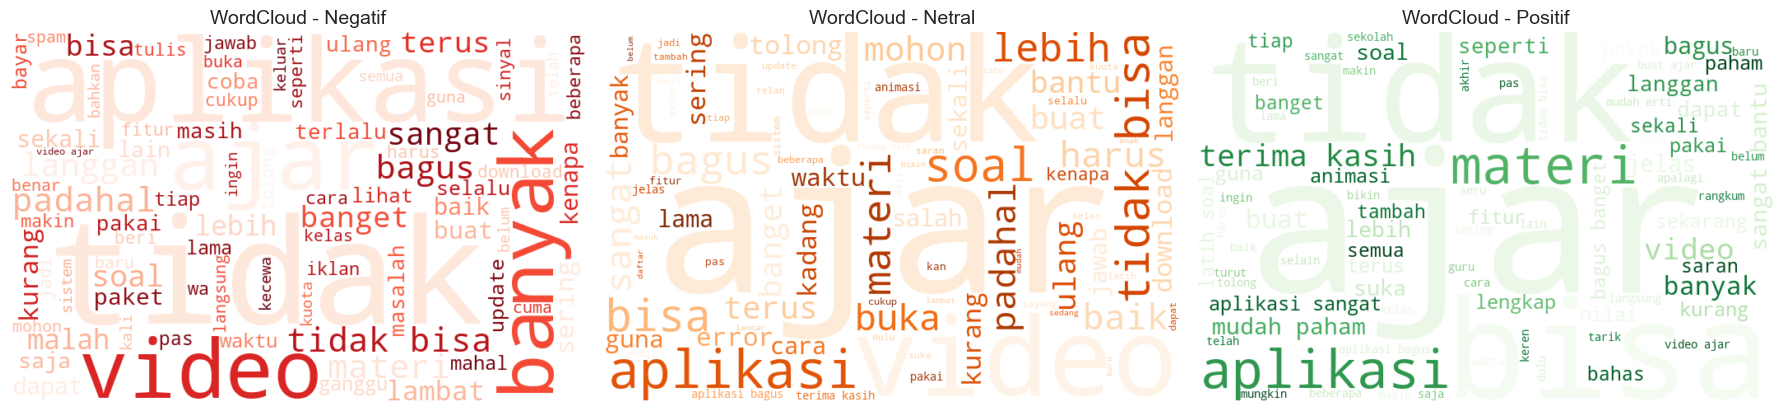

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab in zip(axes, ["Negatif", "Netral", "Positif"]):
    teks = " ".join(df.loc[df["label"] == lab, "clean_content"])
    wc = WordCloud(width=700, height=450, background_color="white", 
                   colormap="Reds" if lab=="Negatif" else "Oranges" if lab=="Netral" else "Greens", 
                   max_words=80, random_state=SEED).generate(teks)
    
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"WordCloud - {lab}", fontsize=14)
    
plt.tight_layout(); plt.show()

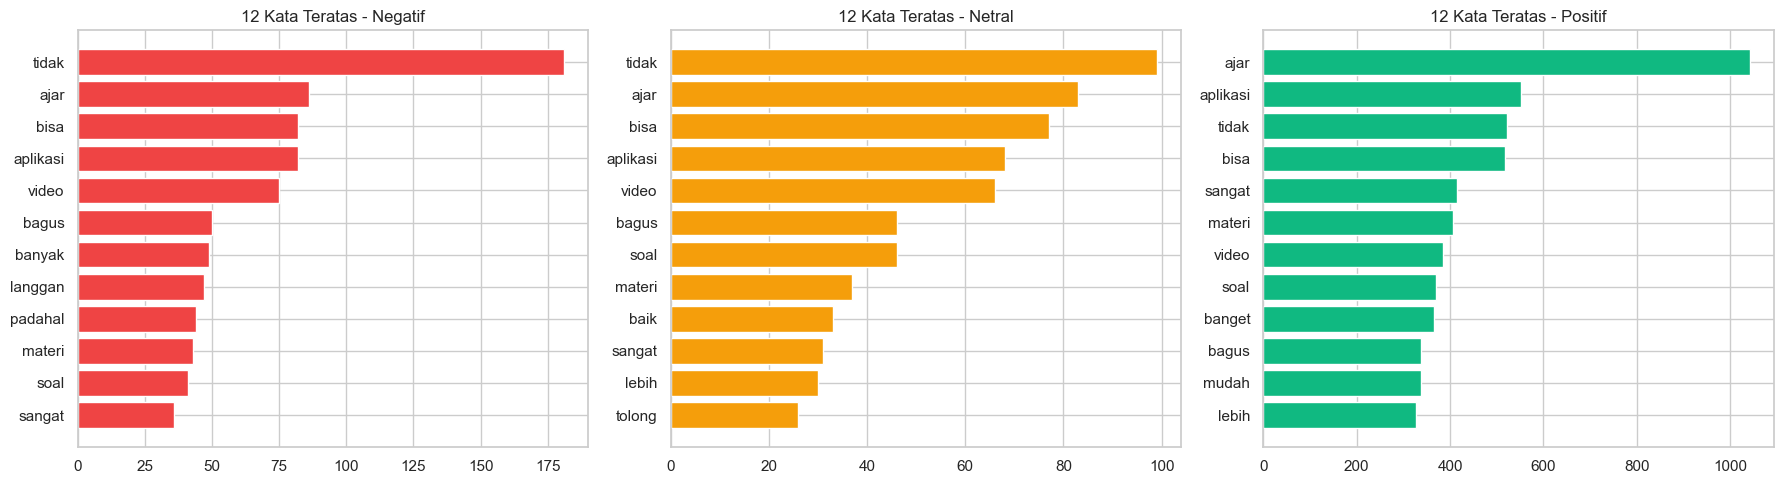

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab in zip(axes, ["Negatif", "Netral", "Positif"]):
    top = pd.Series(" ".join(df.loc[df["label"] == lab, "clean_content"]).split()).value_counts().head(12)[::-1]
    ax.barh(top.index, top.values, color=PALETTE[lab]); ax.set_title(f"12 Kata Teratas - {lab}")
plt.tight_layout(); plt.show()

In [35]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean_content"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED)

print(f"Data latih: {len(X_train_txt)} | Data uji: {len(X_test_txt)}")
pd.DataFrame({"Latih": y_train.value_counts(), "Uji": y_test.value_counts()})

Data latih: 800 | Data uji: 200


,Latih,Uji
label,,
Positif,627,157
Negatif,102,25
Netral,71,18


In [37]:
def buat_sampler(y, faktor=1.0):
    min_n = int(pd.Series(y).value_counts().min() * faktor)
    k = min(5, min_n - 1)
    return SMOTE(k_neighbors=k, random_state=SEED) if k >= 1 else RandomOverSampler(random_state=SEED)

N_FOLD = 5
pipe = ImbPipeline([
    ("tfidf", TfidfVectorizer(sublinear_tf=True)),
    ("smote", buat_sampler(y_train, faktor=(N_FOLD-1)/N_FOLD)),
    ("nb", MultinomialNB()),
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__max_features": [2000, 5000],
    "tfidf__min_df": [1, 2, 3],
    "nb__alpha": [0.05, 0.1, 0.3, 0.5, 1.0],
}

gs = GridSearchCV(pipe, param_grid, scoring="f1_macro",
                  cv=StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED), n_jobs=-1)

gs.fit(X_train_txt, y_train)

print("Parameter terbaik:", gs.best_params_)
print(f"F1-macro CV terbaik: {gs.best_score_:.4f}")

hasil_grid = (pd.DataFrame(gs.cv_results_)[["param_tfidf__ngram_range", "param_tfidf__max_features", "param_tfidf__min_df", "param_nb__alpha", "mean_test_score", "std_test_score"]]
              .rename(columns=lambda c: c.replace("param_", "")).sort_values("mean_test_score", ascending=False))
hasil_grid.head(10)

Parameter terbaik: {'nb__alpha': 0.5, 'tfidf__max_features': 5000, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
F1-macro CV terbaik: 0.5322


,tfidf__ngram_range,tfidf__max_features,tfidf__min_df,nb__alpha,mean_test_score,std_test_score
42,"(1, 1)",5000,1,0.50,0.532186,0.017171
3,"(1, 2)",2000,2,0.05,0.527328,0.042145
43,"(1, 2)",5000,1,0.50,0.526292,0.020244
15,"(1, 2)",2000,2,0.10,0.525811,0.019587
5,"(1, 2)",2000,3,0.05,0.525198,0.030695
11,"(1, 2)",5000,3,0.05,0.525198,0.030695
30,"(1, 1)",5000,1,0.30,0.523937,0.019484
33,"(1, 2)",5000,2,0.30,0.522675,0.029747
45,"(1, 2)",5000,2,0.50,0.522147,0.028889
13,"(1, 2)",2000,1,0.10,0.521519,0.028977


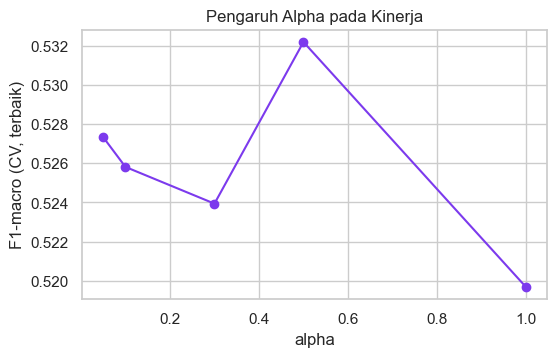

In [38]:
# Pengaruh alpha (Laplace smoothing) terhadap F1-macro
g = hasil_grid.groupby("nb__alpha")["mean_test_score"].max()
plt.figure(figsize=(6, 3.5)); plt.plot(g.index, g.values, marker="o", color="#7C3AED")
plt.xlabel("alpha"); plt.ylabel("F1-macro (CV, terbaik)"); plt.title("Pengaruh Alpha pada Kinerja"); plt.show()

In [39]:
bp = gs.best_params_
vectorizer = TfidfVectorizer(ngram_range=bp["tfidf__ngram_range"], max_features=bp["tfidf__max_features"],
                             min_df=bp["tfidf__min_df"], sublinear_tf=True)
X_train = vectorizer.fit_transform(X_train_txt)      # fit hanya di data latih
X_test = vectorizer.transform(X_test_txt)
print("Bentuk matriks TF-IDF latih:", X_train.shape)

sampler = buat_sampler(y_train)
X_train_bal, y_train_bal = sampler.fit_resample(X_train, y_train)    # SMOTE hanya pada data latih
print(type(sampler).__name__)
pd.DataFrame({"Sebelum": y_train.value_counts(), "Sesudah": pd.Series(y_train_bal).value_counts()})

Bentuk matriks TF-IDF latih: (800, 2770)
SMOTE


,Sebelum,Sesudah
label,,
Positif,627,627
Negatif,102,627
Netral,71,627


In [40]:
model = MultinomialNB(alpha=bp["nb__alpha"])
model.fit(X_train_bal, y_train_bal)
classes = list(model.classes_)
print(f"Model Multinomial Naive Bayes dilatih (alpha={bp['nb__alpha']}), kelas: {classes}")

# 7. Evaluasi Model

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

metrik = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-Score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-Score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
}

tabel_metrik = pd.DataFrame(metrik, index=["Nilai"]).T
display(tabel_metrik.style.format("{:.4f}").background_gradient(cmap="Purples"))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Model Multinomial Naive Bayes dilatih (alpha=0.5), kelas: [np.str_('Negatif'), np.str_('Netral'), np.str_('Positif')]


,Nilai
Accuracy,0.7600
Precision (macro),0.5364
Recall (macro),0.5728
F1-Score (macro),0.5514
F1-Score (weighted),0.7712



Classification Report:

              precision    recall  f1-score   support

     Negatif       0.48      0.60      0.54        25
      Netral       0.23      0.28      0.25        18
     Positif       0.90      0.84      0.87       157

    accuracy                           0.76       200
   macro avg       0.54      0.57      0.55       200
weighted avg       0.79      0.76      0.77       200



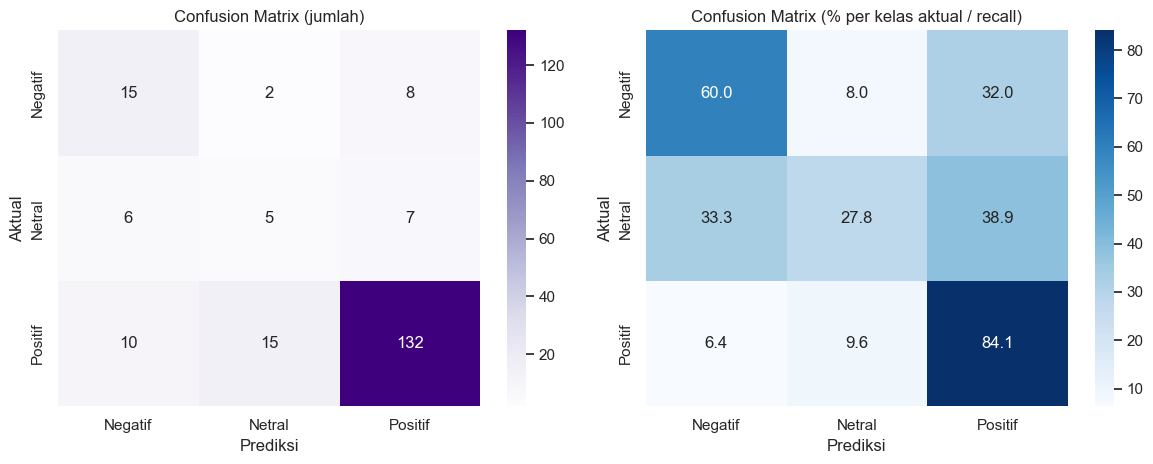

In [41]:
cm = confusion_matrix(y_test, y_pred, labels=classes)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=classes, yticklabels=classes, ax=ax[0])
ax[0].set(title="Confusion Matrix (jumlah)", xlabel="Prediksi", ylabel="Aktual")

sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[1])
ax[1].set(title="Confusion Matrix (% per kelas aktual / recall)", xlabel="Prediksi", ylabel="Aktual")

plt.tight_layout(); plt.show()

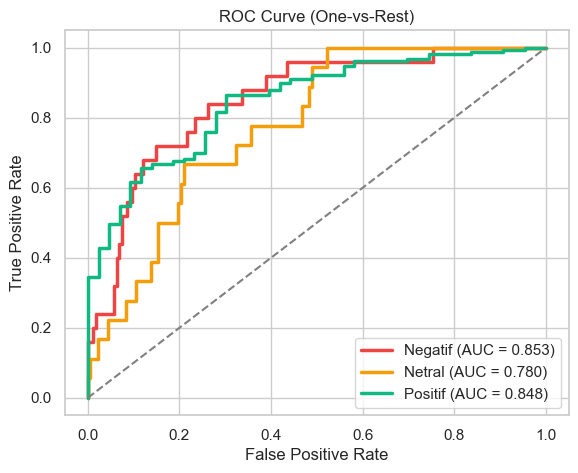

ROC-AUC macro: 0.8271


In [42]:
# ROC Curve One-vs-Rest
Y = label_binarize(y_test, classes=classes)
plt.figure(figsize=(6.5, 5))
aucs = {}
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(Y[:, i], y_prob[:, i])
    aucs[c] = roc_auc_score(Y[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, lw=2.5, color=PALETTE[c], label=f"{c} (AUC = {aucs[c]:.3f})")

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve (One-vs-Rest)")
plt.legend(loc="lower right"); plt.show()
print(f"ROC-AUC macro: {np.mean(list(aucs.values())):.4f}")

,Fold,Accuracy,F1-macro
0,Fold 1,0.7500,0.5250
1,Fold 2,0.7750,0.5167
2,Fold 3,0.8000,0.5639
3,Fold 4,0.7625,0.5360
4,Fold 5,0.7500,0.5194


Accuracy : 0.7675 ± 0.0187
F1-macro : 0.5322 ± 0.0172


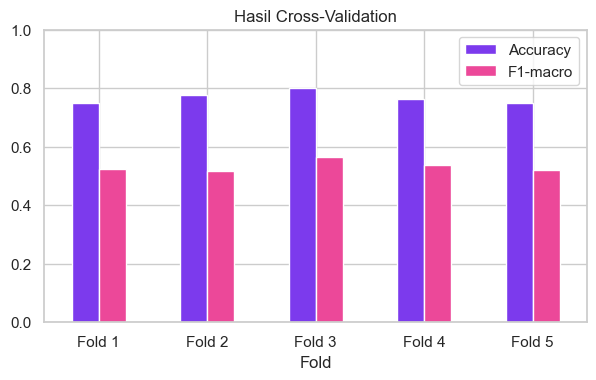

In [43]:
# Cross-Validation pada data latih (TF-IDF + SMOTE dihitung ulang di tiap fold)
best_pipe = ImbPipeline([
    ("tfidf", TfidfVectorizer(ngram_range=bp["tfidf__ngram_range"], max_features=bp["tfidf__max_features"],
                             min_df=bp["tfidf__min_df"], sublinear_tf=True)),
    ("smote", buat_sampler(y_train, faktor=(N_FOLD-1)/N_FOLD)),
    ("nb", MultinomialNB(alpha=bp["nb__alpha"])),
])

skf = StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED)
cv_acc = cross_val_score(best_pipe, X_train_txt, y_train, cv=skf, scoring="accuracy")
cv_f1 = cross_val_score(best_pipe, X_train_txt, y_train, cv=skf, scoring="f1_macro")

cv_df = pd.DataFrame({"Fold": [f"Fold {i+1}" for i in range(N_FOLD)], "Accuracy": cv_acc, "F1-macro": cv_f1})
display(cv_df.style.format({"Accuracy": "{:.4f}", "F1-macro": "{:.4f}"}))
print(f"Accuracy : {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")
print(f"F1-macro : {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")

cv_df.set_index("Fold").plot(kind="bar", figsize=(7, 3.8), color=["#7C3AED", "#EC4899"], rot=0)
plt.ylim(0, 1); plt.title("Hasil Cross-Validation"); plt.show()

In [44]:
# Contoh prediksi yang salah (untuk analisis error)
salah = pd.DataFrame({"ulasan": X_test_txt.values, "aktual": y_test.values, "prediksi": y_pred,
                      "keyakinan": y_prob.max(axis=1)})
salah = salah[salah["aktual"] != salah["prediksi"]].sort_values("keyakinan", ascending=False)
print(f"Jumlah salah prediksi: {len(salah)} dari {len(y_test)}")
salah.head(10)

Jumlah salah prediksi: 48 dari 200


,ulasan,aktual,prediksi,keyakinan
178,hai benar benar terima kasih sangat bantu paha...,Negatif,Positif,0.868216
50,turut aplikasi bagus yah lebih suka baca buku ...,Negatif,Positif,0.827753
156,bantu ajar sekolah sangat kurang bantu guna la...,Netral,Positif,0.777855
93,tolong baik masih banyak kunci jawab salah beb...,Positif,Negatif,0.750945
34,langgan ajar kelas sd materi ipas bahasa indon...,Netral,Positif,0.743643
43,suka fitur ajar lebih senang lebih asix materi...,Positif,Negatif,0.730117
90,hai kenapa waktu pakai selalu sedang jadi masa...,Positif,Negatif,0.727630
149,tidak tau kenapa tidak bisa ngumpulin jawab ti...,Positif,Netral,0.716633
189,aplikasi bagus puas ajar mohon boleh kah tamba...,Positif,Netral,0.705532
155,hy lihat video online lambat amat sering error...,Negatif,Netral,0.698902


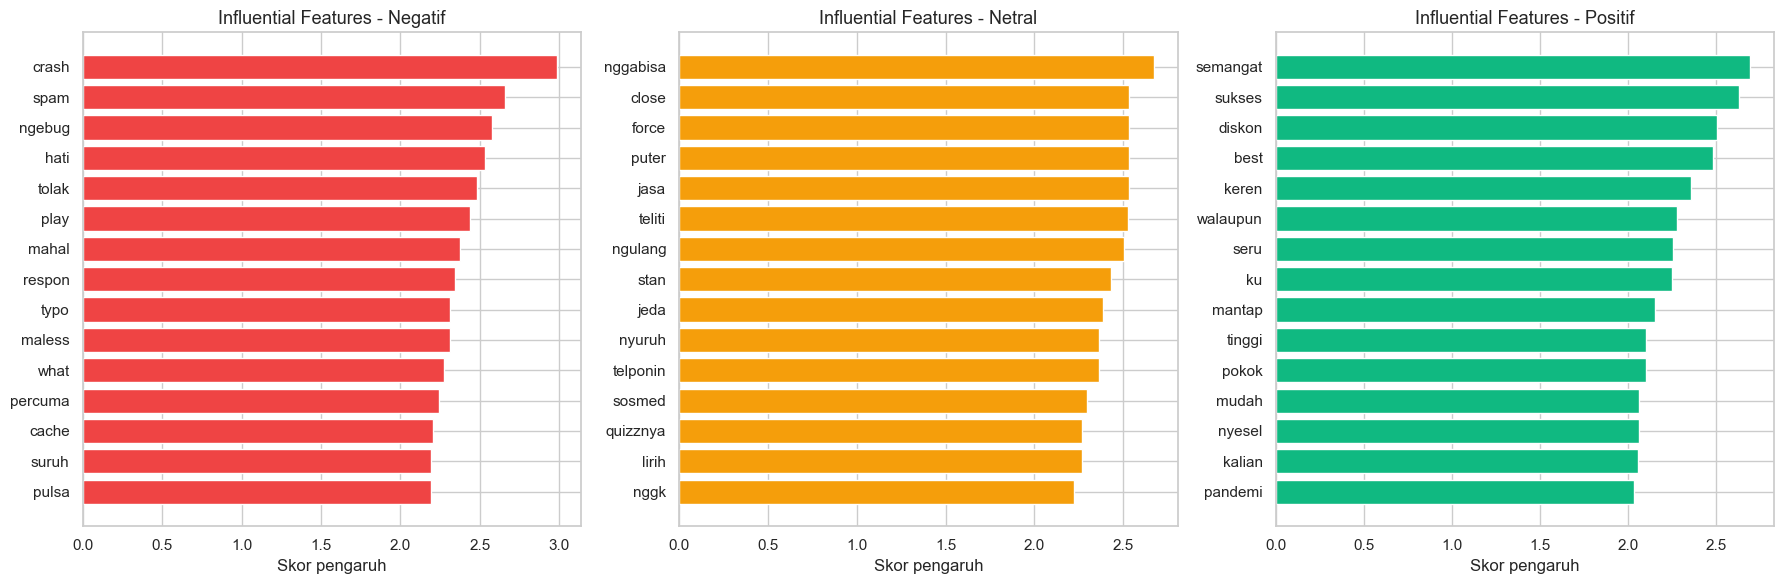

In [45]:
fitur = np.array(vectorizer.get_feature_names_out())
flp = model.feature_log_prob_

def fitur_berpengaruh(top_n=15):
    rows = []
    for i, c in enumerate(classes):
        selisih = flp[i] - np.delete(flp, i, axis=0).mean(axis=0)
        for rank, j in enumerate(np.argsort(selisih)[::-1][:top_n], 1):
            rows.append({"Kelas": c, "Rank": rank, "Fitur": fitur[j], "Skor Pengaruh": selisih[j],
                         "Rasio Odds": np.exp(selisih[j]), "log P(kata|kelas)": flp[i, j]})
    return pd.DataFrame(rows)

inf = fitur_berpengaruh(15)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, c in zip(axes, classes):
    d = inf[inf["Kelas"] == c].sort_values("Skor Pengaruh")
    ax.barh(d["Fitur"], d["Skor Pengaruh"], color=PALETTE[c]); ax.set_title(f"Influential Features - {c}", fontsize=13)
    ax.set_xlabel("Skor pengaruh")
plt.tight_layout(); plt.show()

In [46]:
display(inf.pivot(index="Rank", columns="Kelas", values="Fitur")[classes])

Kelas,Negatif,Netral,Positif
Rank,,,
1,crash,nggabisa,semangat
2,spam,force,sukses
3,ngebug,close,diskon
4,hati,puter,best
5,tolak,jasa,keren
6,play,teliti,walaupun
7,mahal,ngulang,seru
8,respon,stan,ku
9,typo,jeda,mantap


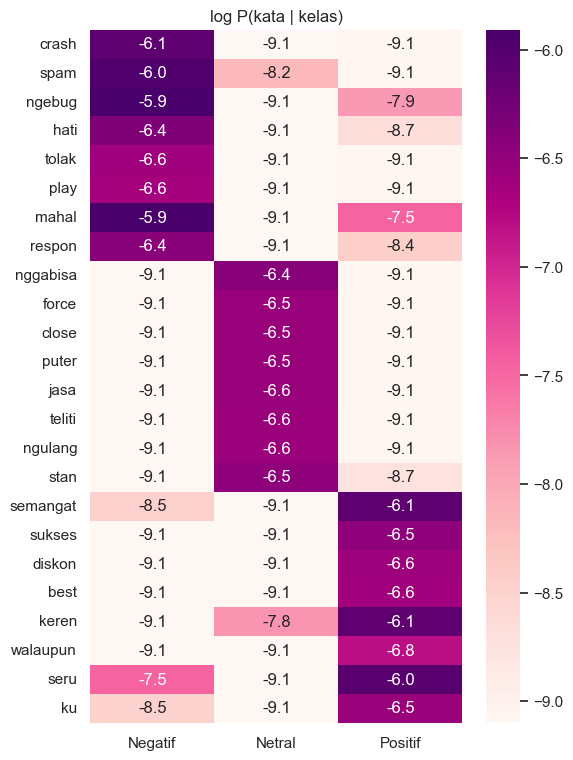

In [47]:
# Heatmap log-probabilitas kata-kata teratas vs kelas
pilih = []
for i in range(len(classes)):
    selisih = flp[i] - np.delete(flp, i, axis=0).mean(axis=0)
    pilih += list(np.argsort(selisih)[::-1][:8])

pilih = list(dict.fromkeys(pilih))
tm = pd.DataFrame(flp[:, pilih].T, index=fitur[pilih], columns=classes)
plt.figure(figsize=(6, 9)); sns.heatmap(tm, annot=True, fmt=".1f", cmap="RdPu"); plt.title("log P(kata | kelas)"); plt.show()

,Aspek,Jumlah,Rata-rata Rating,% Negatif,% Netral,% Positif
0,Materi & Soal,654,4.35,9.3,7.5,83.2
1,Mentor / Guru,638,4.48,6.7,6.6,86.7
2,Video & Animasi,412,4.25,11.2,9.2,79.6
3,Teknis & Performa,316,3.69,23.1,15.2,61.7
4,Fitur & Tampilan,270,4.26,11.1,7.0,81.9
5,Harga & Langganan,266,3.86,22.9,7.9,69.2
6,Layanan & Iklan,61,2.80,49.2,13.1,37.7


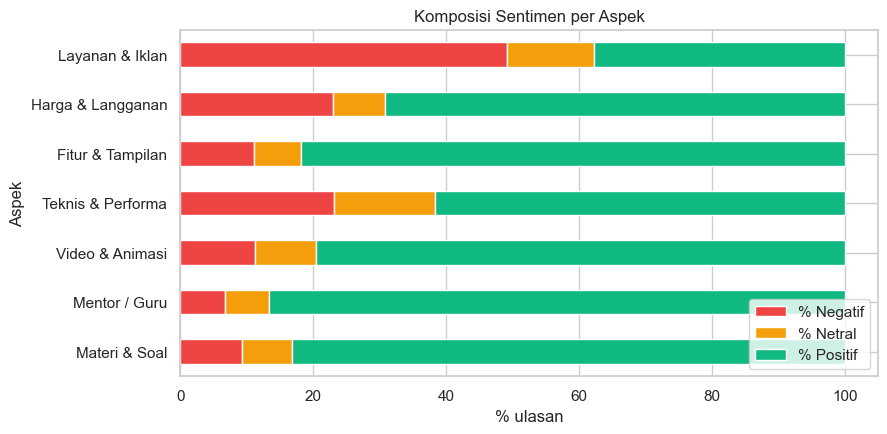

In [48]:
ASPEK = {
    "Mentor / Guru": r"guru|mentor|pengajar|tutor|kakak|penjelasan|menjelaskan",
    "Materi & Soal": r"materi|soal|latihan|rangkuman|pembahasan|kuis|pelajaran|kurikulum|bab",
    "Video & Animasi": r"video|animasi|tayang|nonton|subtitle|suara",
    "Harga & Langganan": r"harga|mahal|langganan|berlangganan|paket|bayar|biaya|promo|diskon|gratis|saldo|refund",
    "Teknis & Performa": r"error|bug|crash|lemot|lambat|loading|download|kuota|login|update|hang|ngelag|tidak bisa|gak bisa|susah",
    "Fitur & Tampilan": r"fitur|tampilan|menu|interface|desain|navigasi|opsi",
    "Layanan & Iklan": r"spam|iklan|telepon|sales|cs|customer|layanan|notifikasi|tawar",
}

low = df["content"].str.lower()
rows = []
for nama, pola in ASPEK.items():
    m = low.str.contains(pola, regex=True); sub = df[m]
    rows.append({"Aspek": nama, "Jumlah": int(m.sum()), "Rata-rata Rating": sub["score"].mean(),
                  "% Negatif": (sub["label"] == "Negatif").mean()*100, "% Netral": (sub["label"] == "Netral").mean()*100,
                  "% Positif": (sub["label"] == "Positif").mean()*100})

asp = pd.DataFrame(rows).sort_values("Jumlah", ascending=False).reset_index(drop=True)
display(asp.style.format({"Rata-rata Rating": "{:.2f}", "% Negatif": "{:.1f}", "% Netral": "{:.1f}", "% Positif": "{:.1f}"}).background_gradient(cmap="Blues"))

asp.set_index("Aspek")[["% Negatif", "% Netral", "% Positif"]].plot(
    kind="barh", stacked=True, figsize=(9, 4.5), color=[PALETTE["Negatif"], PALETTE["Netral"], PALETTE["Positif"]])
plt.xlabel("% ulasan"); plt.title("Komposisi Sentimen per Aspek"); plt.legend(loc="lower right"); plt.show()

In [49]:
def prediksi(teks, top_k=6):
    bersih = bersihkan_teks(teks)
    X = vectorizer.transform([bersih])
    p = model.predict_proba(X)[0]
    pred = classes[p.argmax()]
    kontrib = []
    ref = classes[np.argsort(p)[:-1][1]]
    for j in X.nonzero()[1]:
        kontrib.append((fitur[j], (flp[classes.index(pred), j] - flp[classes.index(ref), j]) * X[0, j]))
    kontrib = sorted(kontrib, key=lambda x: -x[1])[:top_k]
    return pred, dict(zip(classes, p.round(3))), kontrib

for t in ["Aplikasinya bagus banget, materi lengkap dan gurunya jelas!",
            "Sering error, tidak bisa login, kecewa sekali",
            "Lumayan lah tapi masih banyak yang perlu diperbaiki"]:
    pred, prob, kontrib = prediksi(t)
    print(f'"{t}"\n -> {pred} ({prob})\n -> Kata pendorong: {[k for k, _ in kontrib]}')

"Aplikasinya bagus banget, materi lengkap dan gurunya jelas!"
 -> Positif ({np.str_('Negatif'): np.float64(0.069), np.str_('Netral'): np.float64(0.181), np.str_('Positif'): np.float64(0.75)})
 -> Kata pendorong: ['lengkap', 'banget', 'materi', 'jelas', 'guru', 'aplikasi']
"Sering error, tidak bisa login, kecewa sekali"
 -> Netral ({np.str_('Negatif'): np.float64(0.375), np.str_('Netral'): np.float64(0.59), np.str_('Positif'): np.float64(0.036)})
 -> Kata pendorong: ['login', 'error', 'sekali', 'bisa', 'sering', 'tidak']
"Lumayan lah tapi masih banyak yang perlu diperbaiki"
 -> Netral ({np.str_('Negatif'): np.float64(0.125), np.str_('Netral'): np.float64(0.475), np.str_('Positif'): np.float64(0.4)})
 -> Kata pendorong: ['baik', 'masih', 'lumayan', 'banyak', 'perlu']


In [50]:
import joblib

joblib.dump({"vectorizer": vectorizer, "model": model, "classes": classes, "best_params": bp,
             "metrics": metrik, "cm": cm}, "model_nb_sentimen.joblib")

df.to_csv("data_bersih_berlabel.csv", index=False)
print("Tersimpan: model_nb_sentimen.joblib, data_bersih_berlabel.csv, stem_cache.json")

Tersimpan: model_nb_sentimen.joblib, data_bersih_berlabel.csv, stem_cache.json
